# EDA KuaiRand: охват, вовлечённость и ранние сигналы

Ноутбук подготавливает EDA для проекта прогнозирования популярности видео. KuaiRand используется как прокси для TikTok/YouTube: это данные Kuaishou с логами показов и пользовательско-видео взаимодействий.

**Важно:** датасеты TikTok/YouTube и KuaiRand не склеиваются в одну таблицу. KuaiRand закрывает часть проекта про `reach` и `user × video`, а контентные датасеты могут использоваться отдельно. В этом ноутбуке анализируются только файлы KuaiRand.

Официальный источник: [Zenodo KuaiRand](https://zenodo.org/records/10439422). Скачайте KuaiRand-1K или KuaiRand-27K и распакуйте в `data/kuairand/` (либо укажите путь в `DATA_DIR`).

## 1. Цели и проверяемые гипотезы

1. Разделить результат видео на охват и реакцию после показа: `reach` измеряется числом показов, а `engagement` — кликом, лайком, временем просмотра и досмотром.
2. Проверить, связаны ли ранние пользовательские сигналы с последующим охватом.
3. Понять, какие таблицы и признаки доступны для baseline-моделей.
4. Не допустить утечки: статистика, рассчитанная на всём временном горизонте, не должна использоваться как ранний признак для прогноза будущего.

Ограничение интерпретации: `is_show` — факт показа внутри лога, а не рекламный impression в смысле рекламной аналитики; `play_time` может быть записан в миллисекундах согласно схеме конкретной версии, поэтому единицы проверяются эвристикой и явно помечаются.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid')

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'data' / 'kuairand'
RANDOM_STATE = 42
MAX_ROWS_FOR_PLOTS = 2_000_000

print(f'Рабочая директория: {PROJECT_DIR}')
print(f'Ожидаемая директория данных: {DATA_DIR}')

Рабочая директория: /Users/sanya/Documents/hse/TiktokYoutubePrediction
Ожидаемая директория данных: /Users/sanya/Documents/hse/TiktokYoutubePrediction/data/kuairand


In [2]:
csv_files = sorted(DATA_DIR.rglob('*.csv')) if DATA_DIR.exists() else []
if not csv_files:
    raise FileNotFoundError(
        'CSV-файлы KuaiRand не найдены. Скачайте архив с https://zenodo.org/records/10439422, '
        'распакуйте его в data/kuairand/ или измените DATA_DIR в предыдущей ячейке.'
    )

files_table = pd.DataFrame({'path': [str(p) for p in csv_files]})
files_table['size_mb'] = [round(p.stat().st_size / 1024**2, 2) for p in csv_files]
display(files_table)

,path,size_mb
0,/Users/sanya/Documents/hse/TiktokYoutubePredic...,2.94
1,/Users/sanya/Documents/hse/TiktokYoutubePredic...,352.73
2,/Users/sanya/Documents/hse/TiktokYoutubePredic...,0.12


## 2. Загрузка и инвентаризация файлов

Логи могут занимать много места, поэтому сначала читается только заголовок. Для EDA логов используется полный CSV, если он помещается в память; для очень больших файлов включается chunked-профилирование.

In [3]:
def classify_file(path: Path) -> str:
    name = path.name.lower()
    if 'log_' in name or name.startswith('log'):
        return 'log'
    if 'user' in name:
        return 'user_features'
    if 'video' in name or 'item' in name:
        return 'video_features'
    return 'other'

inventory = []
for path in csv_files:
    header = pd.read_csv(path, nrows=0)
    inventory.append({
        'file': path.name,
        'kind': classify_file(path),
        'size_mb': round(path.stat().st_size / 1024**2, 2),
        'n_columns': len(header.columns),
        'columns': ', '.join(header.columns),
    })
inventory_df = pd.DataFrame(inventory)
display(inventory_df[['file', 'kind', 'size_mb', 'n_columns']])
for row in inventory:
    print(f"\n{row['file']} ({row['kind']}):\n  {row['columns']}")

,file,kind,size_mb,n_columns
0,log_random_4_22_to_5_08_1k.csv,log,2.94,19
1,log_standard_4_22_to_5_08_1k.csv,log,352.73,19
2,user_features_1k.csv,user_features,0.12,31



log_random_4_22_to_5_08_1k.csv (log):
  user_id, video_id, date, hourmin, time_ms, is_click, is_like, is_follow, is_comment, is_forward, is_hate, long_view, play_time_ms, duration_ms, profile_stay_time, comment_stay_time, is_profile_enter, is_rand, tab

log_standard_4_22_to_5_08_1k.csv (log):
  user_id, video_id, date, hourmin, time_ms, is_click, is_like, is_follow, is_comment, is_forward, is_hate, long_view, play_time_ms, duration_ms, profile_stay_time, comment_stay_time, is_profile_enter, is_rand, tab

user_features_1k.csv (user_features):
  user_id, user_active_degree, is_lowactive_period, is_live_streamer, is_video_author, follow_user_num, follow_user_num_range, fans_user_num, fans_user_num_range, friend_user_num, friend_user_num_range, register_days, register_days_range, onehot_feat0, onehot_feat1, onehot_feat2, onehot_feat3, onehot_feat4, onehot_feat5, onehot_feat6, onehot_feat7, onehot_feat8, onehot_feat9, onehot_feat10, onehot_feat11, onehot_feat12, onehot_feat13, onehot_feat1

In [4]:
def choose_file(kind: str, preferred_tokens: tuple[str, ...] = ()) -> Path | None:
    candidates = [p for p in csv_files if classify_file(p) == kind]
    for token in preferred_tokens:
        preferred = [p for p in candidates if token in p.name.lower()]
        if preferred:
            return preferred[0]
    return candidates[0] if candidates else None

log_path = choose_file('log', ('standard', 'random'))
user_path = choose_file('user_features')
video_paths = [p for p in csv_files if classify_file(p) == 'video_features']
if log_path is None:
    raise FileNotFoundError('Не найден interaction log CSV: ожидается файл с log_ в имени.')

print('Основной лог:', log_path)
print('Файл пользователей:', user_path)
print('Файлы видео:', video_paths)

log = pd.read_csv(log_path, low_memory=False)
users = pd.read_csv(user_path, low_memory=False) if user_path else None
video_tables = {p.stem: pd.read_csv(p, low_memory=False) for p in video_paths}
print(f'Размер лога: {log.shape}')

Основной лог: /Users/sanya/Documents/hse/TiktokYoutubePrediction/data/kuairand/log_standard_4_22_to_5_08_1k.csv
Файл пользователей: /Users/sanya/Documents/hse/TiktokYoutubePrediction/data/kuairand/user_features_1k.csv
Файлы видео: []


Размер лога: (5003039, 19)


### Проверка схемы и качества данных

In [5]:
def profile_frame(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    result = pd.DataFrame({
        'dtype': frame.dtypes.astype(str),
        'missing': frame.isna().sum(),
        'missing_pct': (frame.isna().mean() * 100).round(2),
        'n_unique': frame.nunique(dropna=True),
    })
    result.index.name = name
    return result.sort_values(['missing_pct', 'n_unique'], ascending=[False, True])

display(profile_frame(log, 'log_column').head(40))
if users is not None:
    print('Профиль user features')
    display(profile_frame(users, 'user_column').head(40))
for name, frame in video_tables.items():
    print(f'Профиль {name}')
    display(profile_frame(frame, 'video_column').head(25))

,dtype,missing,missing_pct,n_unique
log_column,,,,
is_rand,float64,1,0.0,1
is_click,float64,1,0.0,2
is_like,float64,1,0.0,2
is_follow,float64,1,0.0,2
is_comment,float64,1,0.0,2
is_forward,float64,1,0.0,2
is_hate,float64,1,0.0,2
long_view,float64,1,0.0,2
is_profile_enter,float64,1,0.0,2


Профиль user features


,dtype,missing,missing_pct,n_unique
user_column,,,,
onehot_feat12,float64,33,3.3,2
onehot_feat13,float64,33,3.3,2
onehot_feat14,float64,33,3.3,2
onehot_feat15,float64,33,3.3,2
onehot_feat16,float64,33,3.3,2
onehot_feat17,float64,33,3.3,2
onehot_feat4,float64,33,3.3,13
is_lowactive_period,int64,0,0.0,1
is_live_streamer,int64,0,0.0,2


## 3. Признаки и производные метрики

В разных версиях KuaiRand набор названий может немного отличаться. Код ниже выбирает только реально присутствующие колонки и сообщает, какие сигналы отсутствуют.

In [6]:
def first_existing(frame: pd.DataFrame, names: list[str]) -> str | None:
    return next((name for name in names if name in frame.columns), None)

aliases = {
    'show': ['is_show', 'show'],
    'click': ['is_click', 'click'],
    'play': ['is_play', 'play'],
    'like': ['is_like', 'like'],
    'follow': ['is_follow', 'follow'],
    'comment': ['is_comment', 'comment'],
    'forward': ['is_forward', 'forward'],
    'long_view': ['is_long_view', 'long_view', 'is_long_view'],
    'play_time': ['play_time', 'playtime', 'play_time_ms'],
    'complete_play_cnt': ['complete_play_cnt'],
    'timestamp': ['timestamp', 'time', 'time_ms'],
    'user_id': ['user_id', 'userid'],
    'video_id': ['video_id', 'item_id', 'videoid'],
}
resolved = {key: first_existing(log, names) for key, names in aliases.items()}
if resolved['show'] is None:
    log['is_show_proxy'] = 1
    resolved['show'] = 'is_show_proxy'
    print('В логе нет is_show: каждая строка интерпретируется как показ, поэтому CTR — click-per-log-row proxy.')
display(pd.DataFrame({'metric': resolved.keys(), 'column': resolved.values()}))
missing_metrics = [key for key, column in resolved.items() if column is None]
if missing_metrics:
    print('Отсутствуют в этой версии:', missing_metrics)

analysis = log.copy()
for metric in ['show', 'click', 'play', 'like', 'follow', 'comment', 'forward', 'long_view']:
    column = resolved[metric]
    if column is not None:
        analysis[column] = pd.to_numeric(analysis[column], errors='coerce')

def safe_rate(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    return numerator.div(denominator.replace(0, np.nan))

show_col, click_col = resolved['show'], resolved['click']
if show_col and click_col:
    analysis['ctr'] = safe_rate(analysis[click_col], analysis[show_col])
for metric in ['play', 'like', 'follow', 'comment', 'forward', 'long_view']:
    col = resolved[metric]
    if col and show_col:
        analysis[f'{metric}_rate'] = safe_rate(analysis[col], analysis[show_col])

play_time_col = resolved['play_time']
if play_time_col:
    analysis['play_time_raw'] = pd.to_numeric(analysis[play_time_col], errors='coerce')
    median_play_time = analysis['play_time_raw'].median()
    analysis['play_time_seconds'] = analysis['play_time_raw'] / (1000 if median_play_time > 300 else 1)
    print(f'Медиана play_time в исходных единицах: {median_play_time:,.2f}; эвристические секунды рассчитаны.')

В логе нет is_show: каждая строка интерпретируется как показ, поэтому CTR — click-per-log-row proxy.


,metric,column
0,show,is_show_proxy
1,click,is_click
2,play,NaN
3,like,is_like
4,follow,is_follow
5,comment,is_comment
6,forward,is_forward
7,long_view,long_view
8,play_time,play_time_ms
9,complete_play_cnt,NaN


Отсутствуют в этой версии: ['play', 'complete_play_cnt']


Медиана play_time в исходных единицах: 3,217.00; эвристические секунды рассчитаны.


,signal,positive_rate,positive_count,missing_pct
0,is_show_proxy,100.0000%,5003039.000000,0.00%
1,is_click,38.9755%,1949958.000000,0.00%
6,long_view,27.0894%,1355291.000000,0.00%
2,is_like,1.6837%,84236.000000,0.00%
4,is_comment,0.2880%,14407.000000,0.00%
3,is_follow,0.0877%,4389.000000,0.00%
5,is_forward,0.0782%,3910.000000,0.00%


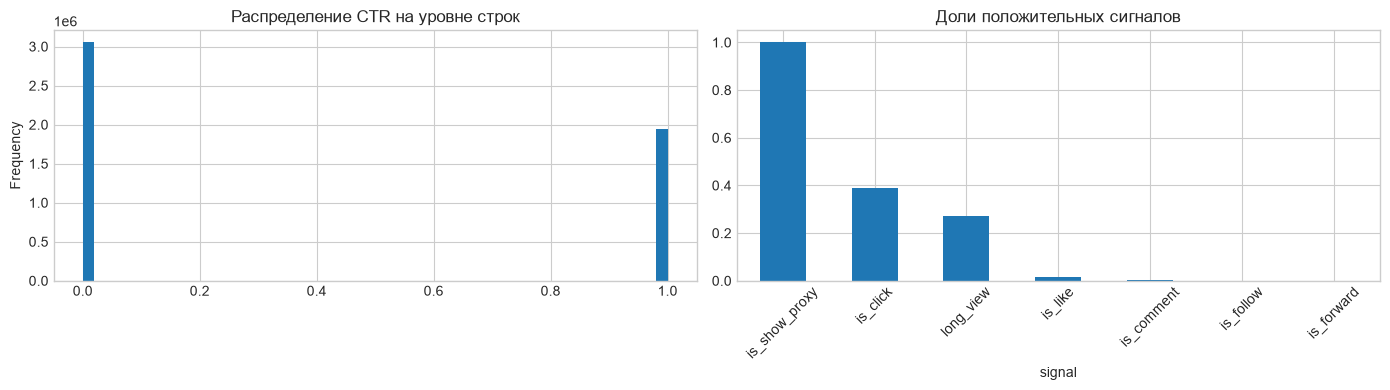

In [7]:
binary_cols = [resolved[key] for key in ['show', 'click', 'play', 'like', 'follow', 'comment', 'forward', 'long_view'] if resolved[key]]
summary_rows = []
for col in binary_cols:
    values = pd.to_numeric(analysis[col], errors='coerce')
    summary_rows.append({
        'signal': col,
        'positive_rate': values.mean(),
        'positive_count': values.sum(),
        'missing_pct': values.isna().mean(),
    })
signal_summary = pd.DataFrame(summary_rows).sort_values('positive_rate', ascending=False)
display(signal_summary.style.format({'positive_rate': '{:.4%}', 'missing_pct': '{:.2%}'}))

if 'ctr' in analysis:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    analysis['ctr'].clip(0, 1).plot.hist(bins=50, ax=axes[0], title='Распределение CTR на уровне строк')
    signal_summary.plot.bar(x='signal', y='positive_rate', ax=axes[1], legend=False, title='Доли положительных сигналов')
    axes[1].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

## 4. Пользовательско-видео уровень и распределения

Строка лога — отдельное наблюдение взаимодействия, поэтому для продуктовых метрик полезно агрегировать по `video_id` и по паре `user_id × video_id`. Для rate-метрик используем агрегированные числитель и знаменатель, а не среднее CTR по строкам.

In [8]:
id_cols = [resolved[key] for key in ['user_id', 'video_id'] if resolved[key]]
if not id_cols:
    raise KeyError('Для агрегации не найдено ни user_id, ни video_id.')

group_cols = [col for col in [resolved['user_id'], resolved['video_id']] if col]
agg_map = {col: ['count'] for col in binary_cols}
for col in [resolved['play_time'], resolved['complete_play_cnt']]:
    if col:
        agg_map[col] = ['sum', 'mean', 'median']
interaction_agg = analysis.groupby(group_cols, dropna=False).agg(agg_map)
interaction_agg.columns = ['_'.join(c).strip('_') for c in interaction_agg.columns]
print('Размер user × video агрегации:', interaction_agg.shape)
display(interaction_agg.describe().T.head(30))

video_id_col = resolved['video_id']
video_agg = analysis.groupby(video_id_col, dropna=False).agg(
    rows=(video_id_col, 'size'),
    users=(resolved['user_id'], 'nunique') if resolved['user_id'] else (video_id_col, 'size'),
    **{f'{metric}_sum': (col, 'sum') for metric, col in [('show', show_col), ('click', click_col), ('play', resolved['play']), ('like', resolved['like']), ('long_view', resolved['long_view'])] if col},
).reset_index()
if show_col and click_col:
    video_agg['ctr'] = safe_rate(video_agg['click_sum'], video_agg['show_sum'])
if show_col and resolved['long_view']:
    video_agg['long_view_rate'] = safe_rate(video_agg['long_view_sum'], video_agg['show_sum'])
display(video_agg.describe(include='all').T)

Размер user × video агрегации: (4863267, 10)


,count,mean,std,min,25%,50%,75%,max
is_show_proxy_count,4863267.0,1.028740,0.181671,1.0,1.0,1.0,1.0,24.0
is_click_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
is_like_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
is_follow_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
is_comment_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
is_forward_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
long_view_count,4863267.0,1.028740,0.181672,0.0,1.0,1.0,1.0,24.0
play_time_ms_sum,4863267.0,15686.911705,35411.329005,0.0,1147.0,3456.0,13783.0,1431951.0
play_time_ms_mean,4863266.0,15487.659489,35098.915436,0.0,1118.0,3365.0,13584.0,1431951.0
play_time_ms_median,4863266.0,15481.040315,35098.653075,0.0,1115.0,3359.0,13574.0,1431951.0


,count,mean,std,min,25%,50%,75%,max
video_id,2161081.0,2.186319e+06,1.261564e+06,16.0,1094763.0,2184726.0,3.279490e+06,4371898.0
rows,2161081.0,2.315063e+00,4.768316e+00,1.0,1.0,1.0,2.000000e+00,471.0
users,2161081.0,2.250386e+00,4.570339e+00,1.0,1.0,1.0,2.000000e+00,303.0
show_sum,2161081.0,2.315063e+00,4.768316e+00,1.0,1.0,1.0,2.000000e+00,471.0
click_sum,2161081.0,9.023068e-01,2.635387e+00,0.0,0.0,0.0,1.000000e+00,215.0
like_sum,2161081.0,3.897864e-02,2.259542e-01,0.0,0.0,0.0,0.000000e+00,18.0
long_view_sum,2161081.0,6.271357e-01,2.099378e+00,0.0,0.0,0.0,1.000000e+00,199.0
ctr,2161081.0,3.262248e-01,4.202855e-01,0.0,0.0,0.0,7.142857e-01,1.0
long_view_rate,2161081.0,2.106466e-01,3.608914e-01,0.0,0.0,0.0,3.333333e-01,1.0


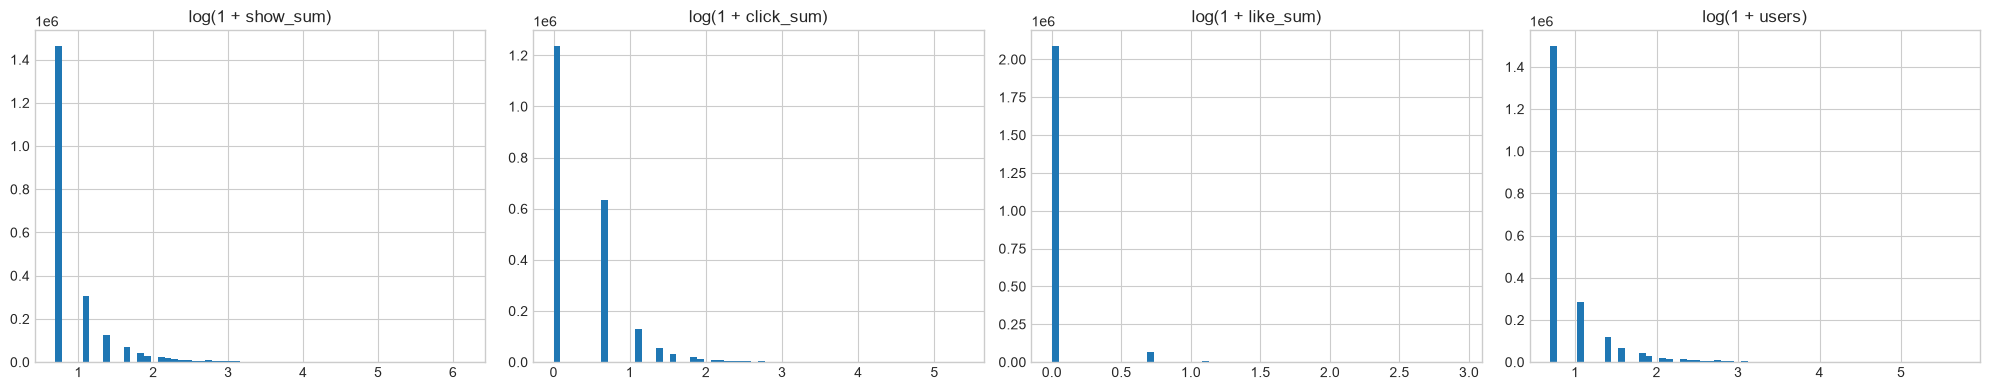

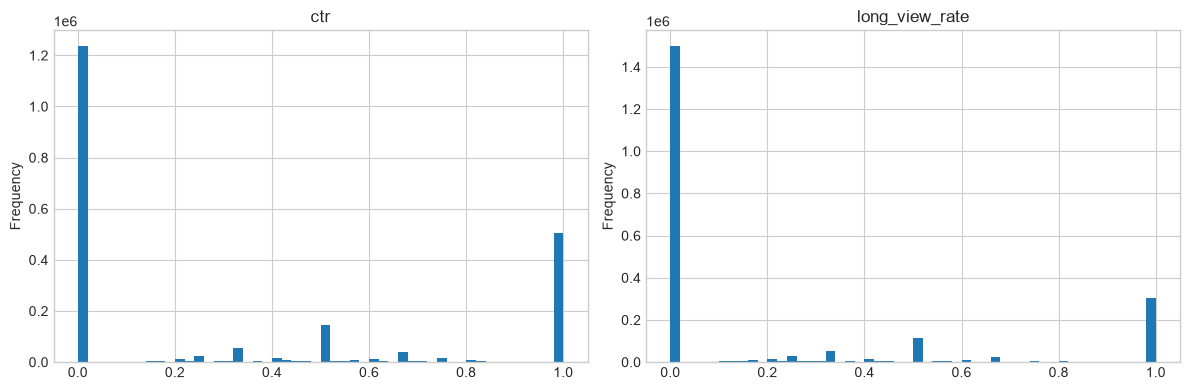

In [9]:
plot_cols = [c for c in ['show_sum', 'click_sum', 'play_sum', 'like_sum', 'users'] if c in video_agg]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(5 * len(plot_cols), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, plot_cols):
    values = video_agg[col].dropna()
    values = values[values >= 0]
    ax.hist(np.log1p(values), bins=60)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

rate_cols = [c for c in ['ctr', 'long_view_rate'] if c in video_agg]
if rate_cols:
    fig, axes = plt.subplots(1, len(rate_cols), figsize=(6 * len(rate_cols), 4))
    for ax, col in zip(np.atleast_1d(axes), rate_cols):
        video_agg[col].clip(0, 1).plot.hist(bins=50, ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

## 5. Временная динамика и ранние сигналы

Временной сплит предпочтительнее случайного: он ближе к будущему применению сервиса. Для каждого дня смотрим объём показов и агрегированные rates. Если timestamp имеет другую единицу, это будет видно по получившемуся диапазону.

Единица timestamp: ms
Диапазон: 2022-04-21 15:03:36.981000 — 2022-05-08 15:52:09.022000


,datetime,rows,shows,clicks,likes,ctr
0,2022-04-21,41087,41087,16404.0,482.0,0.399250
1,2022-04-22,287615,287615,113776.0,4447.0,0.395584
2,2022-04-23,310559,310559,122395.0,5565.0,0.394112
3,2022-04-24,264370,264370,102101.0,3860.0,0.386205
4,2022-04-25,264606,264606,102678.0,3429.0,0.388041


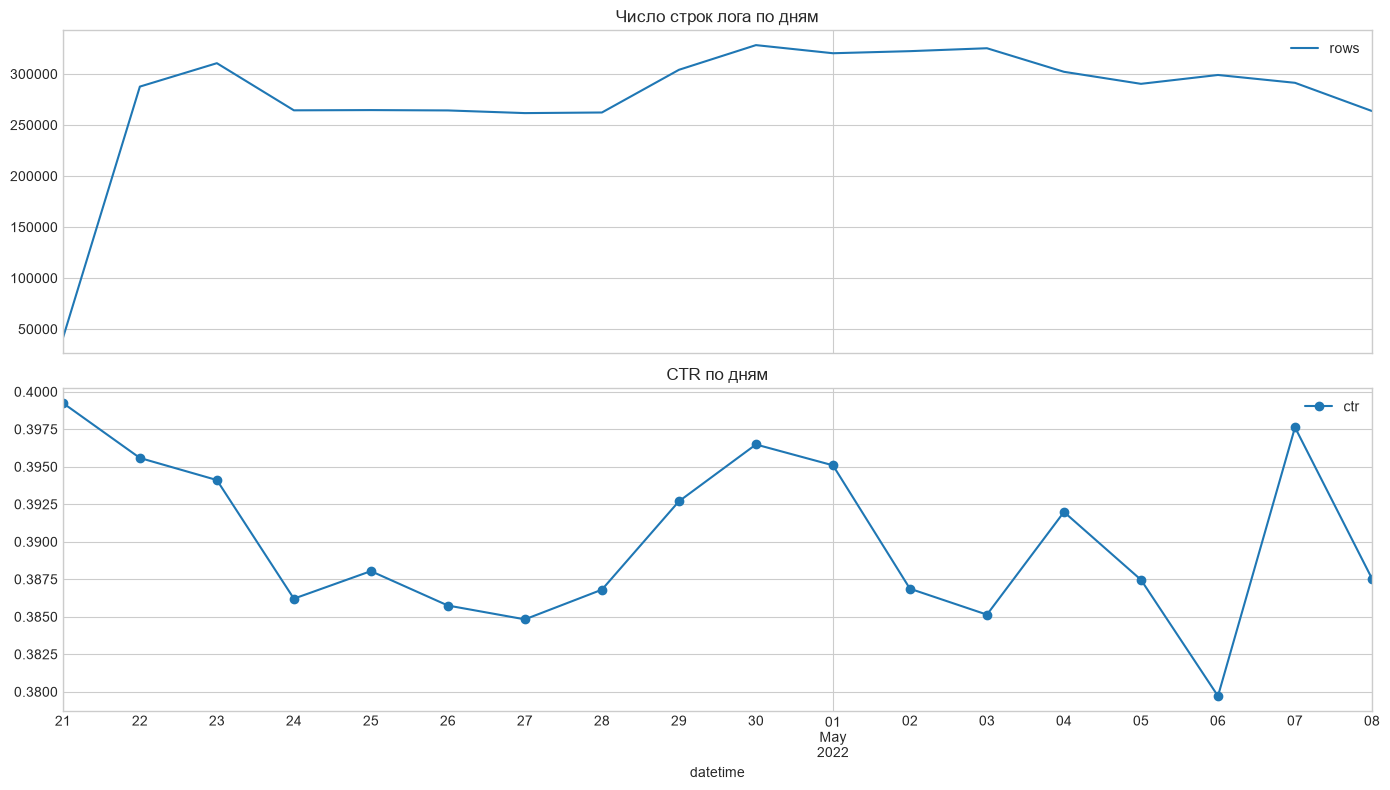

In [10]:
timestamp_col = resolved['timestamp']
if timestamp_col:
    raw_ts = pd.to_numeric(log[timestamp_col], errors='coerce')
    unit = 'ms' if raw_ts.median() > 10**11 else 's'
    analysis['datetime'] = pd.to_datetime(raw_ts, unit=unit, errors='coerce')
    print('Единица timestamp:', unit)
    print('Диапазон:', analysis['datetime'].min(), '—', analysis['datetime'].max())
    daily = analysis.set_index('datetime').resample('D').agg(
        rows=(timestamp_col, 'size'),
        **({
            'shows': (show_col, 'sum'),
            'clicks': (click_col, 'sum'),
            'likes': (resolved['like'], 'sum'),
        } if show_col and click_col else {'rows_again': (timestamp_col, 'size')})
    ).reset_index()
    if 'shows' in daily and 'clicks' in daily:
        daily['ctr'] = safe_rate(daily['clicks'], daily['shows'])
    display(daily.head())
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    daily.plot(x='datetime', y='rows', ax=axes[0], title='Число строк лога по дням')
    if 'ctr' in daily:
        daily.plot(x='datetime', y='ctr', ax=axes[1], title='CTR по дням', marker='o')
    plt.tight_layout()
    plt.show()
else:
    print('Timestamp отсутствует: временной split и анализ ранней динамики по этому файлу невозможны.')

In [11]:
if 'datetime' in analysis and video_id_col:
    first_day = analysis['datetime'].min().normalize()
    cutoffs = [1, 3, 7]
    early_rows = []
    for days in cutoffs:
        period = analysis[analysis['datetime'] < first_day + pd.Timedelta(days=days)]
        early = period.groupby(video_id_col).agg(early_rows=(video_id_col, 'size'))
        if show_col:
            early['early_shows'] = period.groupby(video_id_col)[show_col].sum()
        if click_col:
            early['early_clicks'] = period.groupby(video_id_col)[click_col].sum()
        early['window_days'] = days
        early_rows.append(early.reset_index())
    early_by_window = pd.concat(early_rows, ignore_index=True)
    display(early_by_window.groupby('window_days').size().rename('videos_with_signal').to_frame())
    print('Для прогноза будущего охвата используйте признаки из окна 1–3 дня и target после этого окна;')
    print('не используйте полные show/click/like totals, иначе возникает temporal leakage.')
else:
    print('Ранние сигналы не рассчитаны: нужен timestamp и video_id.')

,videos_with_signal
window_days,
1,33615
3,366030
7,848977


Для прогноза будущего охвата используйте признаки из окна 1–3 дня и target после этого окна;
не используйте полные show/click/like totals, иначе возникает temporal leakage.


## 6. Проверка random vs standard и источника охвата

Если в логе есть `policy`, сравним режимы показа. Random-логи особенно полезны для оценки реакции на видео при уменьшении bias рекомендательной системы; standard-логи ближе к обычному трафику, но сильнее отражают работу самой рекомендации.

In [12]:
policy_col = first_existing(log, ['policy', 'is_rand', 'tab', 'source'])
if policy_col and show_col:
    policy_summary = analysis.groupby(policy_col).agg(
        rows=(policy_col, 'size'),
        shows=(show_col, 'sum'),
        clicks=(click_col, 'sum') if click_col else (show_col, 'sum'),
    )
    if click_col:
        policy_summary['ctr'] = safe_rate(policy_summary['clicks'], policy_summary['shows'])
    display(policy_summary.sort_values('rows', ascending=False))
else:
    print('Колонка policy не найдена; сравнение random и standard недоступно для выбранного файла.')

,rows,shows,clicks,ctr
is_rand,,,,
0.0,5003038,5003038,1949958.0,0.389755


## 7. Выводы для постановки ML-задач

По результатам этого ноутбука следует зафиксировать в отчёте:

- **Основной объект:** показ/взаимодействие `user × video`; для recommendation можно строить implicit-feedback матрицу.
- **Engagement targets:** `is_click`, `is_play`, `is_like`, `is_long_view`, `play_time_seconds`; rates считать с агрегированным знаменателем `show`.
- **Reach target:** `show_cnt` на видео за заданное будущее окно. Если дневной video-level статистики нет, `show` в логах — прокси охвата внутри наблюдаемого лога.
- **Прямая baseline-задача:** по доступным до cutoff признакам предсказать `log1p(future_show_cnt)` или `log1p(future_play_cnt)`.
- **Декомпозиция:** (1) предсказать engagement после показа; (2) предсказать будущий reach; (3) сравнить с прямым прогнозом views. Не использовать будущие interaction totals как вход.
- **Временная валидация:** train на раннем периоде, validation на следующем, test на последнем; случайный split оставить только как диагностический.
- **Критическое ограничение:** в KuaiRand нет публичного TikTok/YouTube CTR. Поэтому в тексте проекта корректно назвать это прокси-исследованием Kuaishou, а не прямым измерением TikTok/YouTube.
- **Контент:** подписи/категории и другие content-features анализировать отдельными таблицами; не склеивать с другими датасетами по несуществующим ID. При необходимости сравнивать датасеты через общий CLIP/текстовый encoder.

После запуска замените этот список фактическими числами из таблиц выше: размер лога, число пользователей/видео, диапазон дат, доли сигналов, квантили `show_cnt`, CTR и long-view rate.

## 6. Рабочая постановка: дневной охват и future targets

Комментарий преподавателя уточняет роль KuaiRand: это основной прокси для `reach` и `user × video`, а не источник реального TikTok/YouTube CTR. Поэтому следующий слой анализа строится на дневных агрегатах. В текущей выгрузке нет отдельного `is_show`, `show_cnt`, `play_cnt`, `complete_play_cnt`; каждая строка лога используется как proxy-показ, а доступные `is_click`, `long_view`, `play_time_ms` — как engagement-сигналы.

Целевая схема для следующего этапа:

```text
video × early window  →  future reach / future plays
                         future engagement
```

Другие датасеты (MicroLens, TikTok, SnapUGC) не присоединяются по ID: они закрывают контент, hook и retention отдельными экспериментами.

In [13]:
# Дневная таблица video × date: базовый слой для reach-модели.
# Важно: в этой выгрузке shows — proxy числа строк лога.
if 'datetime' not in analysis:
    raise RuntimeError('Для daily-агрегации нужен timestamp/time_ms.')

analysis['date_day'] = analysis['datetime'].dt.floor('D')
daily_agg = analysis.groupby([video_id_col, 'date_day'], dropna=False).agg(
    show_cnt=(video_id_col, 'size'),
    user_cnt=(resolved['user_id'], 'nunique') if resolved['user_id'] else (video_id_col, 'size'),
    click_cnt=(click_col, 'sum') if click_col else (video_id_col, 'size'),
    like_cnt=(resolved['like'], 'sum') if resolved['like'] else (video_id_col, 'size'),
    long_view_cnt=(resolved['long_view'], 'sum') if resolved['long_view'] else (video_id_col, 'size'),
    play_time_ms=(resolved['play_time'], 'sum') if resolved['play_time'] else (video_id_col, 'size'),
).reset_index()
daily_agg['ctr_proxy'] = safe_rate(daily_agg['click_cnt'], daily_agg['show_cnt'])
daily_agg['long_view_rate'] = safe_rate(daily_agg['long_view_cnt'], daily_agg['show_cnt'])
daily_agg['avg_play_time_ms'] = safe_rate(daily_agg['play_time_ms'], daily_agg['show_cnt'])
print('Размер daily video table:', daily_agg.shape)
display(daily_agg.head())
display(daily_agg[['show_cnt','user_cnt','click_cnt','like_cnt','long_view_cnt','ctr_proxy','long_view_rate','avg_play_time_ms']].describe(percentiles=[.5,.75,.9,.95,.99]).T)

Размер daily video table: (3247680, 11)


,video_id,date_day,show_cnt,user_cnt,click_cnt,like_cnt,long_view_cnt,play_time_ms,ctr_proxy,long_view_rate,avg_play_time_ms
0,16,2022-05-08,1,1,0.0,0.0,0.0,1906.0,0.0,0.0,1906.0
1,19,2022-04-23,1,1,0.0,0.0,0.0,6694.0,0.0,0.0,6694.0
2,19,2022-04-25,1,1,0.0,0.0,0.0,1178.0,0.0,0.0,1178.0
3,19,2022-05-05,1,1,0.0,0.0,0.0,2196.0,0.0,0.0,2196.0
4,21,2022-04-29,2,2,0.0,0.0,0.0,4128.0,0.0,0.0,2064.0


,count,mean,std,min,50%,75%,90%,95%,99%,max
show_cnt,3247680.0,1.540496,2.267698,1.0,1.0,1.0,2.0,4.0,10.000,317.0
user_cnt,3247680.0,1.506047,2.167527,1.0,1.0,1.0,2.0,4.0,9.000,234.0
click_cnt,3247680.0,0.600416,1.344885,0.0,0.0,1.0,1.0,2.0,5.000,161.0
like_cnt,3247680.0,0.025937,0.167558,0.0,0.0,0.0,0.0,0.0,1.000,8.0
long_view_cnt,3247680.0,0.417311,1.106468,0.0,0.0,1.0,1.0,2.0,4.000,153.0
ctr_proxy,3247680.0,0.358191,0.452008,0.0,0.0,1.0,1.0,1.0,1.000,1.0
long_view_rate,3247680.0,0.240460,0.400470,0.0,0.0,0.5,1.0,1.0,1.000,1.0
avg_play_time_ms,3247680.0,14084.931861,31662.809962,0.0,3214.0,12751.0,37388.5,65571.0,153591.605,1431951.0


In [14]:
# Повторные показы и разреженность: насколько надёжны video-level rates.
video_repetition = daily_agg.groupby(video_id_col).agg(
    active_days=('date_day', 'nunique'),
    total_show_cnt=('show_cnt', 'sum'),
    total_click_cnt=('click_cnt', 'sum'),
    total_long_view_cnt=('long_view_cnt', 'sum'),
).reset_index()
video_repetition['total_ctr_proxy'] = safe_rate(video_repetition['total_click_cnt'], video_repetition['total_show_cnt'])
video_repetition['total_long_view_rate'] = safe_rate(video_repetition['total_long_view_cnt'], video_repetition['total_show_cnt'])
print('Видео:', len(video_repetition))
print('Доля видео с одним proxy-показом:', (video_repetition['total_show_cnt'].eq(1)).mean())
print('Доля видео с 3+ proxy-показами:', (video_repetition['total_show_cnt'].ge(3)).mean())
print('Доля видео с 2+ активными днями:', (video_repetition['active_days'].ge(2)).mean())
display(video_repetition[['total_show_cnt','active_days','total_ctr_proxy','total_long_view_rate']].describe(percentiles=[.5,.75,.9,.95,.99]).T)

Видео: 2161081
Доля видео с одним proxy-показом: 0.6763513260261879
Доля видео с 3+ proxy-показами: 0.18139070215322795
Доля видео с 2+ активными днями: 0.24466412873927446


,count,mean,std,min,50%,75%,90%,95%,99%,max
total_show_cnt,2161081.0,2.315063,4.768316,1.0,1.0,2.000000,4.0,7.0,19.0,471.0
active_days,2161081.0,1.502803,1.246493,1.0,1.0,1.000000,3.0,4.0,7.0,18.0
total_ctr_proxy,2161081.0,0.326225,0.420285,0.0,0.0,0.714286,1.0,1.0,1.0,1.0
total_long_view_rate,2161081.0,0.210647,0.360891,0.0,0.0,0.333333,1.0,1.0,1.0,1.0


### Формирование раннего окна и будущего target

Для первого эксперимента используем окно:

- `early_days = 1`: признаки первого дня;
- `future_days = 7`: target следующих семи дней;
- видео должно иметь наблюдения и в early, и в future периоде.

Это не утверждает, что видео было опубликовано именно в первый день: в текущем логе отсутствует надёжная дата публикации. Поэтому постановка называется **forecasting after cutoff**, а не прогнозом сразу после публикации. Для строгого cold-start потребуется дата появления видео из дополнительных таблиц.

In [15]:
# Temporal feature/target table. Cutoff — первый день наблюдаемого периода + early_days.
EARLY_DAYS = 1
FUTURE_DAYS = 7
period_start = daily_agg['date_day'].min()
cutoff = period_start + pd.Timedelta(days=EARLY_DAYS)
future_end = cutoff + pd.Timedelta(days=FUTURE_DAYS)

early = daily_agg[daily_agg['date_day'] < cutoff].groupby(video_id_col).agg(
    early_show_cnt=('show_cnt', 'sum'),
    early_click_cnt=('click_cnt', 'sum'),
    early_like_cnt=('like_cnt', 'sum'),
    early_long_view_cnt=('long_view_cnt', 'sum'),
    early_play_time_ms=('play_time_ms', 'sum'),
).reset_index()
early['early_ctr_proxy'] = safe_rate(early['early_click_cnt'], early['early_show_cnt'])
early['early_long_view_rate'] = safe_rate(early['early_long_view_cnt'], early['early_show_cnt'])

future = daily_agg[(daily_agg['date_day'] >= cutoff) & (daily_agg['date_day'] < future_end)].groupby(video_id_col).agg(
    future_show_cnt=('show_cnt', 'sum'),
    future_click_cnt=('click_cnt', 'sum'),
    future_like_cnt=('like_cnt', 'sum'),
    future_long_view_cnt=('long_view_cnt', 'sum'),
    future_play_time_ms=('play_time_ms', 'sum'),
).reset_index()
future['future_ctr_proxy'] = safe_rate(future['future_click_cnt'], future['future_show_cnt'])
future['future_long_view_rate'] = safe_rate(future['future_long_view_cnt'], future['future_show_cnt'])

temporal_dataset = early.merge(future, on=video_id_col, how='inner')
temporal_dataset['target_log_future_show_cnt'] = np.log1p(temporal_dataset['future_show_cnt'])
temporal_dataset['target_log_future_play_time_ms'] = np.log1p(temporal_dataset['future_play_time_ms'])
print('Cutoff:', cutoff, '| future end:', future_end)
print('Temporal dataset:', temporal_dataset.shape)
display(temporal_dataset.describe().T)

Cutoff: 2022-04-22 00:00:00 | future end: 2022-04-29 00:00:00
Temporal dataset: (15957, 17)


,count,mean,std,min,25%,50%,75%,max
video_id,15957.0,2.177388e+06,1.261934e+06,29.000000,1.094153e+06,2.174950e+06,3.271653e+06,4.371581e+06
early_show_cnt,15957.0,1.372000e+00,1.337266e+00,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,4.700000e+01
early_click_cnt,15957.0,6.251175e-01,9.922441e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,3.300000e+01
early_like_cnt,15957.0,1.278436e-02,1.129029e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00
early_long_view_cnt,15957.0,4.541580e-01,8.874249e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,3.400000e+01
early_play_time_ms,15957.0,2.568248e+04,5.798975e+04,0.000000,1.429000e+03,6.113000e+03,2.454600e+04,2.031608e+06
early_ctr_proxy,15957.0,4.405773e-01,4.732677e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
early_long_view_rate,15957.0,3.128609e-01,4.403310e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
future_show_cnt,15957.0,5.129598e+00,8.412662e+00,1.000000,1.000000e+00,3.000000e+00,6.000000e+00,1.910000e+02
future_click_cnt,15957.0,2.393495e+00,4.756072e+00,0.000000,0.000000e+00,1.000000e+00,3.000000e+00,1.370000e+02


Early features: ['early_show_cnt', 'early_click_cnt', 'early_like_cnt', 'early_long_view_cnt', 'early_play_time_ms', 'early_ctr_proxy', 'early_long_view_rate']
Future targets/diagnostics: ['future_show_cnt', 'future_click_cnt', 'future_like_cnt', 'future_long_view_cnt', 'future_play_time_ms', 'future_ctr_proxy', 'future_long_view_rate', 'target_log_future_show_cnt', 'target_log_future_play_time_ms']


,corr_with_future_reach
target_log_future_show_cnt,1.000000
early_show_cnt,0.346569
early_click_cnt,0.288442
early_long_view_cnt,0.257817
early_play_time_ms,0.178389
early_ctr_proxy,0.073179
early_long_view_rate,0.061437
early_like_cnt,0.021396


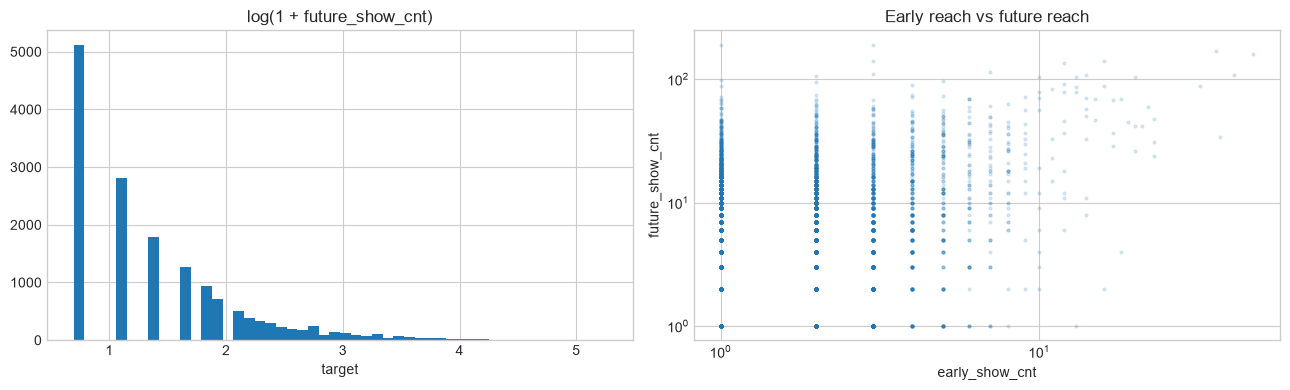

In [16]:
# Простая проверка: ранние сигналы действительно доступны до target и не используют future-поля.
early_cols = [c for c in temporal_dataset.columns if c.startswith('early_')]
future_cols = [c for c in temporal_dataset.columns if c.startswith('future_') or c.startswith('target_')]
print('Early features:', early_cols)
print('Future targets/diagnostics:', future_cols)

correlation_candidates = [c for c in early_cols if c in temporal_dataset]
if correlation_candidates:
    corr = temporal_dataset[correlation_candidates + ['target_log_future_show_cnt']].corr(numeric_only=True)['target_log_future_show_cnt'].sort_values(ascending=False)
    display(corr.to_frame('corr_with_future_reach'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(temporal_dataset['target_log_future_show_cnt'], bins=50)
axes[0].set_title('log(1 + future_show_cnt)')
axes[0].set_xlabel('target')
axes[1].scatter(temporal_dataset['early_show_cnt'], temporal_dataset['future_show_cnt'], s=4, alpha=.15)
axes[1].set_xscale('symlog', linthresh=1)
axes[1].set_yscale('symlog', linthresh=1)
axes[1].set_xlabel('early_show_cnt')
axes[1].set_ylabel('future_show_cnt')
axes[1].set_title('Early reach vs future reach')
plt.tight_layout()
plt.show()

## 7. Что именно пойдёт в ML и что остаётся отдельными экспериментами

### KuaiRand: основная reach/engagement часть

1. **Engagement baseline:** предсказывать `is_click`, `long_view`, `is_like` на уровне `user × video × context`.
2. **Reach baseline:** предсказывать `log1p(future_show_cnt)` по признакам раннего окна.
3. **Прямой подход:** `X_early → log1p(future_show_cnt)` или `log1p(future_play_cnt)`, когда будет доступен отдельный `play_cnt`.
4. **Декомпозиция:** сначала предсказать engagement и reach, затем использовать их для итогового прогноза будущих просмотров/plays.
5. **Валидация:** временной split; случайный split не использовать как основной из-за утечки будущего поведения.

### Отдельные датасеты

- TikTok/MicroLens: `content → log1p(views)` и `content → log1p(likes)`; отсутствие CTR не мешает.
- SnapUGC: `first_5_seconds → retention_after_5s`, то есть отдельная проверка гипотезы про hook.
- Общий CLIP/text encoder может дать сравнимые embeddings, но исходные строки и ID объединять не нужно.
- KuaiRec использовать для дневной динамики, если требуется более чистая video-level постановка.

### Ограничение текущей выгрузки

В текущем HF CSV нет `show_cnt`, `play_cnt`, `complete_play_cnt` как отдельных полей и нет контентных подписей/категорий. Поэтому результаты этой версии — корректный EDA interaction log с proxy-показами. Для финальной reach-модели нужно дополнительно загрузить официальные дневные video statistics/контентные таблицы KuaiRand с Zenodo.

In [17]:
# Сохраняем новые слои для baseline и MLflow dataset version.
OUTPUT_DIR = PROJECT_DIR / 'artifacts' / 'kuairand_eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
daily_agg.to_csv(OUTPUT_DIR / 'video_daily_proxy.csv', index=False)
video_repetition.to_csv(OUTPUT_DIR / 'video_repetition_summary.csv', index=False)
temporal_dataset.to_csv(OUTPUT_DIR / 'temporal_reach_dataset_1d_7d.csv', index=False)
metadata = {
    'dataset': 'KuaiRand-1K HF numberbeat6/kuairand',
    'source_log': log_path.name,
    'show_definition': 'one log row = proxy show; no is_show in HF CSV',
    'early_days': EARLY_DAYS,
    'future_days': FUTURE_DAYS,
    'period_start': str(period_start),
    'cutoff': str(cutoff),
    'future_end': str(future_end),
    'n_log_rows': int(len(log)),
    'n_daily_rows': int(len(daily_agg)),
    'n_temporal_videos': int(len(temporal_dataset)),
}
(Path(OUTPUT_DIR) / 'temporal_dataset_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print('Сохранены daily/repetition/temporal таблицы и metadata в', OUTPUT_DIR)

Сохранены daily/repetition/temporal таблицы и metadata в /Users/sanya/Documents/hse/TiktokYoutubePrediction/artifacts/kuairand_eda


## 8. Сохранение промежуточных таблиц

CSV-результаты можно использовать в следующем этапе baseline. Файлы сохраняются только после успешной загрузки и агрегации.

In [18]:
OUTPUT_DIR = PROJECT_DIR / 'artifacts' / 'kuairand_eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
signal_summary.to_csv(OUTPUT_DIR / 'signal_summary.csv', index=False)
video_agg.to_csv(OUTPUT_DIR / 'video_aggregates.csv', index=False)
if 'daily' in globals():
    daily.to_csv(OUTPUT_DIR / 'daily_metrics.csv', index=False)
print('Сохранено в:', OUTPUT_DIR)


Сохранено в: /Users/sanya/Documents/hse/TiktokYoutubePrediction/artifacts/kuairand_eda
